# A03 Process Capability: Dar es Salaam hibiscus yield

**Ubuntu Naturals Co-operative, Dar es Salaam primary processing (Tanzania, Tier 3, value-chain Stage 2).**
Worked exemplar prepared by the DigiSkills programme team. A learner's file would be named
`A03_Process_Capability_<Surname>.ipynb`.

The Dar es Salaam line dries, grinds and sieves hibiscus calyx for the Hibiscus Pressure
tablets made in Johannesburg. Its quality record is a daily shift return typed into Excel:
one row a day with the shift, the hall's ambient temperature, the line's energy use and the
yield. A good day, in the plant's own register, is a yield of at least 75 %. Nobody
reads 90 days of those rows by eye, so this notebook does, and asks four questions:

1. Can the record be trusted as it stands?
2. Is the yield process stable, and is it capable against the 75 % floor?
3. What drives the bad days?
4. What should be watched automatically, and how would a warning be raised early enough to act?

## Summary for the plant

- The record needed 16 cells fixing in 16 of its 91 rows before any statistic could be trusted, including one energy reading logged in MWh and one ambient temperature of 320 °C.
- Yield averaged 77.39 % with a standard deviation of 1.38 points. It is stable: no day falls outside the control limits or breaks a run rule, and the one moving-range signal is a jump up to the best day of the run. The process today is the process it will be tomorrow.
- It is not capable. Cpk is 0.62 and Ppk 0.58, far short of the 1.33 most customers expect. 6 of 89 days (6.7 %) fell below the floor; the normal model expects about 41,600 days in a million, or one day in 24.
- Hot days explain much of the gap. On days above 25 °C yield averaged 76.61 % against 77.90 % on cooler days. Removing that loss alone would lift Cpk to about 0.86.
- A lower-side CUSUM tuned to raise a false alarm about once in 12 months catches a slow yield decline of 0.1 points a day in a median 14 days. A 7-day rolling z-score held to the same false-alarm budget catches only 22 % of such declines within 30 days.

## Contents

1. [Set-up](#1.-Set-up)
2. [Load the shift returns and check them](#2.-Load-the-shift-returns-and-check-them)
3. [Exploratory data analysis](#3.-Exploratory-data-analysis)
4. [Normality](#4.-Normality)
5. [Control charts](#5.-Control-charts)
6. [Capability](#6.-Capability)
7. [Anomaly detection and early warning](#7.-Anomaly-detection-and-early-warning)
8. [Recommendations for the Dar es Salaam quality manager](#8.-Recommendations-for-the-Dar-es-Salaam-quality-manager)
9. [Figures used in this narrative](#9.-Figures-used-in-this-narrative)

## Where this differs from the Port Louis brief

The brief's Port Louis line logs pasteuriser temperature every second and fill volume in
subgroups of five. Dar es Salaam has neither: it is a Tier 3 plant on daily Excel returns.
So every method in the brief is applied here at daily resolution. The Individuals/Moving
Range chart, the normality tests and the anomaly detectors run on the daily yield series;
the X-bar/R chart uses consecutive 5-day subgroups, and the notebook says what that
choice costs. The code is written so the same functions would take a 1-second sensor
series unchanged.

## 1. Set-up

Everything the notebook needs is in the cell below: the libraries, the random seed for the
one simulation in section 7, the specification and the analysis choices. Change a choice
here and every section follows it.

In [1]:
# Requirements: Python 3.11+, pandas, numpy, scipy, matplotlib, scikit-learn
#   pip install pandas numpy scipy matplotlib scikit-learn
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

SEED = 2026                   # fixes the threshold simulation in section 7
LSL = 75.0                    # yield floor, %: the plant register's "Yield % >= 75%"
BASELINE_DAYS = 30            # phase I window the control limits are fitted on
SUBGROUP_N = 5                # consecutive days per X-bar/R subgroup
HOT_C = 25.0                  # ambient temperature where the yield loss starts (section 3)
TARGET_CPK = 1.33             # the capability most customers write into a contract

# The data sits in the W06 workshop folder; a copy saved beside the notebook also works.
DATA = Path("../../workshops/06_excel_to_ai_dashboarding/graduate/group_assets/"
            "dar_es_salaam_hibiscus_90d.csv")
if not DATA.exists():
    DATA = Path("dar_es_salaam_hibiscus_90d.csv")

C = {"yield": "#0072B2", "energy": "#E69F00", "ambient": "#009E73", "alarm": "#D55E00",
     "spec": "#D55E00", "limit": "#222222", "muted": "#9AA3AD", "zone": "#0072B2"}
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "legend.frameon": False})
pd.set_option("display.precision", 3)

## 2. Load the shift returns and check them

The file is read as text first. Reading it straight into numbers would let pandas guess,
and a guess is exactly what hides a unit typed into a cell. The header lines that start
with `#` are provenance notes, not data.

In [2]:
raw = pd.read_csv(DATA, comment="#", dtype=str, keep_default_na=False)
print(f"Loaded {DATA.name}: {raw.shape[0]} rows x {raw.shape[1]} columns")
print("Columns:", ", ".join(raw.columns))
raw.head(8)

Loaded dar_es_salaam_hibiscus_90d.csv: 91 rows x 6 columns
Columns: date, shift, ambient_temp_c, energy_kwh, yield_pct, notes


,date,shift,ambient_temp_c,energy_kwh,yield_pct,notes
0,2025-08-01,C,28.4,915.3,75.98,
1,2025-08-02,A,25.9,735.6,74.68,
2,2025-08-03,A,23.3,807.7,78.79,
3,2025-08-04,a,25.4,879.1,77.89,
4,2025-08-05,C,22.9,730.5,77.08,
5,01/08/2025,A,24.9,822.9,77.48,
6,2025-08-07,B,22.9,864.1,79.05,
7,2025-08-08,A,,758.2,78.44,sensor outage


In [3]:
NUMERIC = ["ambient_temp_c", "energy_kwh", "yield_pct"]


def parse_number(text):
    """Read one logged value. Returns (number or NaN, what was wrong with it or None)."""
    t = str(text).strip()
    if t == "":
        return np.nan, "blank"
    if t.lower() in {"n/a", "na", "-"}:
        return np.nan, "not a number"
    problem = None
    if t.endswith("%"):
        t, problem = t[:-1].strip(), "percent sign"
    if t.lower().endswith("kwh"):
        t, problem = t[:-3].strip(), "unit typed in the cell"
    if "," in t:
        t, problem = t.replace(",", "."), "decimal comma"
    return float(t), problem


def triage(raw):
    """One row per problem cell, so nothing is fixed silently. Rows are numbered from 1."""
    found = []
    for i in raw.index[raw.duplicated(keep="first")]:
        found.append((i + 1, "whole row", "exact duplicate of an earlier row", ""))
    for col in NUMERIC:
        for i, text in raw[col].items():
            problem = parse_number(text)[1]
            if problem:
                found.append((i + 1, col, problem, text))
    shift = raw["shift"]
    for i in shift.index[shift != shift.str.strip().str.upper()]:
        found.append((i + 1, "shift", "case or spaces", repr(shift[i])))
    iso = pd.to_datetime(raw["date"], format="%Y-%m-%d", errors="coerce")
    for i in raw.index[iso.isna()]:
        found.append((i + 1, "date", "not an ISO date", raw.at[i, "date"]))
    return pd.DataFrame(found, columns=["row", "column", "problem", "as logged"])


issues = triage(raw)
print(f"{len(issues)} problem cells in {issues['row'].nunique()} of {len(raw)} rows")
issues

16 problem cells in 16 of 91 rows


,row,column,problem,as logged
0,91,whole row,exact duplicate of an earlier row,
1,8,ambient_temp_c,blank,
2,20,ambient_temp_c,blank,
3,42,ambient_temp_c,blank,
4,64,ambient_temp_c,blank,
5,13,energy_kwh,unit typed in the cell,812.4 kWh
6,23,energy_kwh,blank,
7,56,energy_kwh,decimal comma,"879,2"
8,72,energy_kwh,blank,
9,31,yield_pct,percent sign,76.1%


The triage finds 16 problem cells in 16 rows. They are the ordinary
faults of a hand-typed return: blanks where the ambient sensor was out, a unit typed into a
number, a decimal comma, a percent sign, an `n/a`, shift letters with stray spaces, dates in
three formats, and one row entered twice. Two more faults do not show as text problems
because they parse as numbers. One energy reading is 0.82 (the meter's note
says to check it), which is plainly MWh in a kWh column. One ambient temperature is
320 °C, which no hall in Dar es Salaam reaches; it is most likely a slipped
decimal point, but it cannot be repaired with confidence, so it is set to missing.

The rules applied below are written down in the function, and every change is logged.
The raw table is never edited, which is what ALCOA+ asks of a quality record: the original
entry stays readable beside the correction.

In [4]:
START = pd.Timestamp("2025-08-01")


def parse_date(text):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%m/%d/%y"):
        try:
            return pd.to_datetime(text.strip(), format=fmt)
        except ValueError:
            pass
    return pd.NaT


def clean(raw):
    """Return (one row per day, audit log). `raw` is left untouched."""
    log = []
    df = raw.drop_duplicates(keep="first").reset_index(drop=True)
    log.append(("whole row", f"{len(raw) - len(df)} exact duplicate row removed"))
    # One shift return per day, in date order, so the row position is the day.
    expected = START + pd.to_timedelta(np.arange(len(df)), unit="D")
    logged = df["date"].map(parse_date)
    for i in np.flatnonzero(logged.values != expected.values):
        log.append(("date", f"row {i + 1}: logged {df.at[i, 'date']!r}, the sequence says "
                            f"{expected[i]:%Y-%m-%d}; sequence kept"))
    df["date"] = expected
    df["shift"] = df["shift"].str.strip().str.upper()
    for col in NUMERIC:
        df[col] = [parse_number(t)[0] for t in df[col]]
    mwh = df["energy_kwh"] < 10
    for i in np.flatnonzero(mwh):
        log.append(("energy_kwh", f"row {i + 1}: {df.at[i, 'energy_kwh']} is MWh; x1000"))
    df.loc[mwh, "energy_kwh"] *= 1000
    impossible = df["ambient_temp_c"] > 50
    for i in np.flatnonzero(impossible):
        log.append(("ambient_temp_c", f"row {i + 1}: {df.at[i, 'ambient_temp_c']} °C is not "
                                      "possible; set missing"))
    df.loc[impossible, "ambient_temp_c"] = np.nan
    df["day"] = np.arange(1, len(df) + 1)
    df["hot_day"] = df["ambient_temp_c"].gt(HOT_C).where(df["ambient_temp_c"].notna())
    return df, pd.DataFrame(log, columns=["column", "action"])


daily, audit = clean(raw)
print(f"{len(daily)} days, {daily['date'].min():%d %b %Y} to {daily['date'].max():%d %b %Y}")
print("Values present per column:", daily[NUMERIC].notna().sum().to_dict())
audit

90 days, 01 Aug 2025 to 29 Oct 2025
Values present per column: {'ambient_temp_c': 85, 'energy_kwh': 88, 'yield_pct': 89}


,column,action
0,whole row,1 exact duplicate row removed
1,date,"row 6: logged '01/08/2025', the sequence says ..."
2,date,"row 28: logged '8/27/25', the sequence says 20..."
3,energy_kwh,row 45: 0.82 is MWh; x1000
4,ambient_temp_c,row 59: 320.0 °C is not possible; set missing


After cleaning there are 90 days, 89 of them with a yield. The rest of the
notebook works on this table.

## 3. Exploratory data analysis

In [5]:
def describe(s):
    s = s.dropna()
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "sd": s.std(),
                      "min": s.min(), "max": s.max(), "range": s.max() - s.min(),
                      "skewness": s.skew(), "excess kurtosis": s.kurt()})


summary = pd.DataFrame({c: describe(daily[c]) for c in NUMERIC}).round(2)
summary

,ambient_temp_c,energy_kwh,yield_pct
n,85.00,88.00,89.00
mean,24.02,823.01,77.39
median,23.90,826.85,77.56
sd,3.37,92.53,1.38
min,14.80,590.30,74.08
max,30.30,1030.20,81.15
range,15.50,439.90,7.07
skewness,-0.21,-0.27,-0.09
excess kurtosis,-0.26,-0.36,0.04


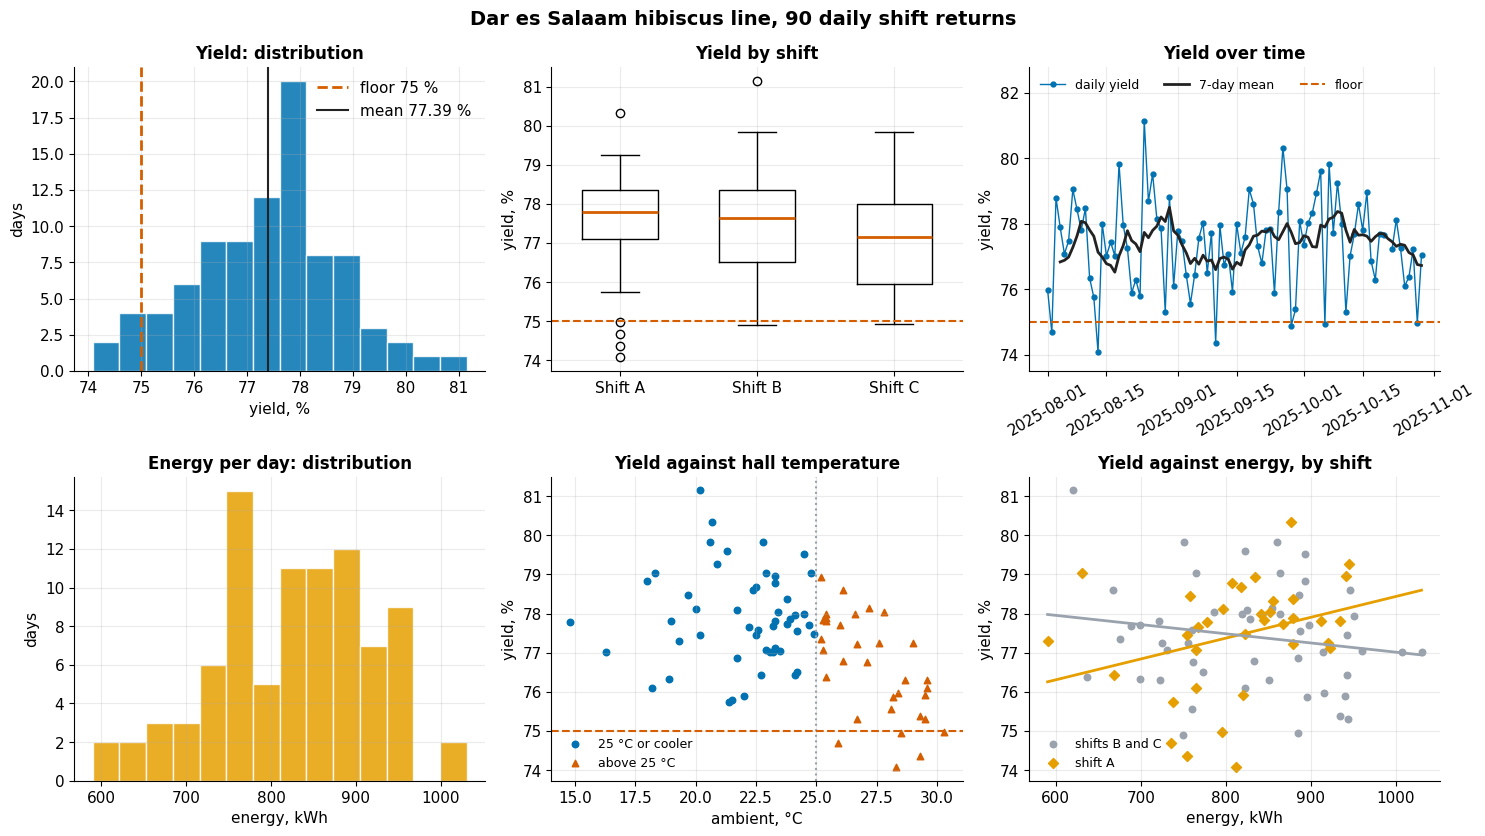

In [6]:
y = daily["yield_pct"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
fig.suptitle("Dar es Salaam hibiscus line, 90 daily shift returns", fontsize=14, fontweight="bold")

a = ax[0, 0]
a.hist(y.dropna(), bins=14, color=C["yield"], alpha=0.85, edgecolor="white")
a.axvline(LSL, color=C["spec"], ls="--", lw=2, label=f"floor {LSL:.0f} %")
a.axvline(y.mean(), color=C["limit"], lw=1.5, label=f"mean {y.mean():.2f} %")
a.set(title="Yield: distribution", xlabel="yield, %", ylabel="days")
a.legend()

a = ax[0, 1]
shifts = sorted(daily["shift"].unique())
a.boxplot([daily.loc[daily["shift"] == s, "yield_pct"].dropna() for s in shifts],
          tick_labels=[f"Shift {s}" for s in shifts], widths=0.55,
          medianprops={"color": C["alarm"], "lw": 2})
a.axhline(LSL, color=C["spec"], ls="--", lw=1.5)
a.set(title="Yield by shift", ylabel="yield, %")

a = ax[0, 2]
a.plot(daily["date"], y, "o-", color=C["yield"], ms=3.5, lw=1, label="daily yield")
a.plot(daily["date"], y.rolling(7, min_periods=4).mean(), color=C["limit"], lw=2,
       label="7-day mean")
a.axhline(LSL, color=C["spec"], ls="--", lw=1.5, label="floor")
a.set(title="Yield over time", ylabel="yield, %", ylim=(73.5, 82.8))
a.legend(loc="upper left", ncols=3, fontsize=9)
a.tick_params(axis="x", rotation=30)

a = ax[1, 0]
e = daily["energy_kwh"]
a.hist(e.dropna(), bins=14, color=C["energy"], alpha=0.85, edgecolor="white")
a.set(title="Energy per day: distribution", xlabel="energy, kWh", ylabel="days")

a = ax[1, 1]
known = daily.dropna(subset=["ambient_temp_c", "yield_pct"])
hot = known["hot_day"].astype(bool)
a.scatter(known.loc[~hot, "ambient_temp_c"], known.loc[~hot, "yield_pct"], s=22,
          color=C["yield"], label=f"{HOT_C:.0f} °C or cooler")
a.scatter(known.loc[hot, "ambient_temp_c"], known.loc[hot, "yield_pct"], s=22,
          color=C["alarm"], marker="^", label=f"above {HOT_C:.0f} °C")
a.axvline(HOT_C, color=C["muted"], ls=":", lw=1.5)
a.axhline(LSL, color=C["spec"], ls="--", lw=1.5)
a.set(title="Yield against hall temperature", xlabel="ambient, °C", ylabel="yield, %")
a.legend(loc="lower left", fontsize=9)

a = ax[1, 2]
both = daily.dropna(subset=["energy_kwh", "yield_pct"])
is_a = both["shift"] == "A"
a.scatter(both.loc[~is_a, "energy_kwh"], both.loc[~is_a, "yield_pct"], s=22,
          color=C["muted"], label="shifts B and C")
a.scatter(both.loc[is_a, "energy_kwh"], both.loc[is_a, "yield_pct"], s=26,
          color=C["energy"], marker="D", label="shift A")
for sel, col in ((is_a, C["energy"]), (~is_a, C["muted"])):
    b1, b0 = np.polyfit(both.loc[sel, "energy_kwh"], both.loc[sel, "yield_pct"], 1)
    xs = np.linspace(both["energy_kwh"].min(), both["energy_kwh"].max(), 2)
    a.plot(xs, b0 + b1 * xs, color=col, lw=2)
a.set(title="Yield against energy, by shift", xlabel="energy, kWh", ylabel="yield, %")
a.legend(loc="lower left", fontsize=9)

fig.tight_layout()
plt.show()

### What the plots say

Yield sits in a narrow band, 74.08 to 81.15 %,
around a mean of 77.39 % and a median of 77.56 %. The histogram is
close to symmetric (skewness -0.09, excess kurtosis 0.04) and the time
series shows no trend: the 7-day mean wanders but does not walk away. The floor of
75 % sits only 1.7 standard deviations below the mean, which is the whole
problem in one sentence, and section 6 measures it.

The box plots show no shift is clearly better than another. Energy use is also roughly
symmetric, around 823 kWh a day with a standard deviation of 93 kWh.

The two bottom-right panels hold the non-obvious findings, and the next cell tests them:

The first is heat. Below about 25 °C the hall temperature makes little visible
difference to yield; above it, yield falls away, and hot days are where the low days come
from. The second is energy on shift A only. On shift A, days that used more energy seem to
give more yield, while on shifts B and C the line is flat or falls slightly. If it holds up,
something shift A does with the extra energy (a longer dry, a slower mill feed) is worth
finding out.

In [7]:
corr = daily[NUMERIC].corr().round(2)
known = daily.dropna(subset=["ambient_temp_c", "yield_pct"])
hot_y = known.loc[known["hot_day"].astype(bool), "yield_pct"]
cool_y = known.loc[~known["hot_day"].astype(bool), "yield_pct"]
t_hot = stats.ttest_ind(hot_y, cool_y, equal_var=False)
f_shift = stats.f_oneway(*[g.dropna() for _, g in daily.groupby("shift")["yield_pct"]])
both = daily.dropna(subset=["energy_kwh", "yield_pct"])
r_a = stats.pearsonr(*both.loc[both["shift"] == "A", ["energy_kwh", "yield_pct"]].T.values)
r_bc = stats.pearsonr(*both.loc[both["shift"] != "A", ["energy_kwh", "yield_pct"]].T.values)
acf1 = daily["yield_pct"].autocorr(lag=1)

print(f"Hot days (> {HOT_C:.0f} °C): n={len(hot_y)}, mean {hot_y.mean():.2f} %")
print(f"Cool days:            n={len(cool_y)}, mean {cool_y.mean():.2f} %")
print(f"  Welch t = {t_hot.statistic:.2f}, p = {t_hot.pvalue:.5f}")
print(f"Shift means differ? one-way ANOVA F = {f_shift.statistic:.2f}, p = {f_shift.pvalue:.3f}")
print(f"Energy vs yield, shift A:     r = {r_a.statistic:.2f}, p = {r_a.pvalue:.3f}")
print(f"Energy vs yield, shifts B, C: r = {r_bc.statistic:.2f}, p = {r_bc.pvalue:.3f}")
print(f"Lag-1 autocorrelation of daily yield: {acf1:.2f}")
corr

Hot days (> 25 °C): n=33, mean 76.61 %
Cool days:            n=51, mean 77.90 %
  Welch t = -4.59, p = 0.00002
Shift means differ? one-way ANOVA F = 0.58, p = 0.562
Energy vs yield, shift A:     r = 0.31, p = 0.067
Energy vs yield, shifts B, C: r = -0.17, p = 0.217
Lag-1 autocorrelation of daily yield: 0.09


,ambient_temp_c,energy_kwh,yield_pct
ambient_temp_c,1.00,0.09,-0.48
energy_kwh,0.09,1.00,0.01
yield_pct,-0.48,0.01,1.00


Hall temperature has the strongest link to yield (r = -0.48); energy on its
own shows almost none (r = 0.01) because the shift A effect is diluted by the
other two shifts. Split by shift a pattern appears: r = 0.31 on shift A,
r = -0.17 on B and C. It is not proven. With 35 shift A days the p-value is
0.067, above the usual 0.05, so it is a lead to follow up with a trial, not a finding
to act on. Hot days lost 1.29 points of yield on average
(Welch p = 0.00002). The shifts do not differ in mean yield (ANOVA p = 0.56).

The lag-1 autocorrelation is 0.09: one day's yield says almost nothing about the next.
That matters for section 5, because control limits built on the moving range assume the
days are independent, and here they are.

### Hypotheses carried forward

(1) The process is stable but its spread is too wide for the
floor, so it will chart in control and still fail capability. (2) A large part of the
spread is heat, which is a cause that can be removed, not noise that has to be lived with.
(3) The shift A energy pattern is a lead, not a result. (4) An early-warning detector has to find slow decline, the shape a fouling dryer or a run
of hot weather would make, not only single bad days.

## 4. Normality

The control limits and the defect rates in sections 5 and 6 lean on the normal model. Two
tests check it: Shapiro-Wilk, which has good power at this sample size, and
Anderson-Darling, which weights the tails, where the floor is. Energy is tested twice,
cleaned and as logged, to show what one bad entry does.

                          n  Shapiro-Wilk W   SW p  Anderson-Darling A2  AD p (table, capped at 0.15)
yield %                89.0           0.991  0.805                0.374                          0.15
energy kWh, cleaned    88.0           0.985  0.379                0.434                          0.15
energy kWh, as logged  88.0           0.785  0.000                2.141                          0.01


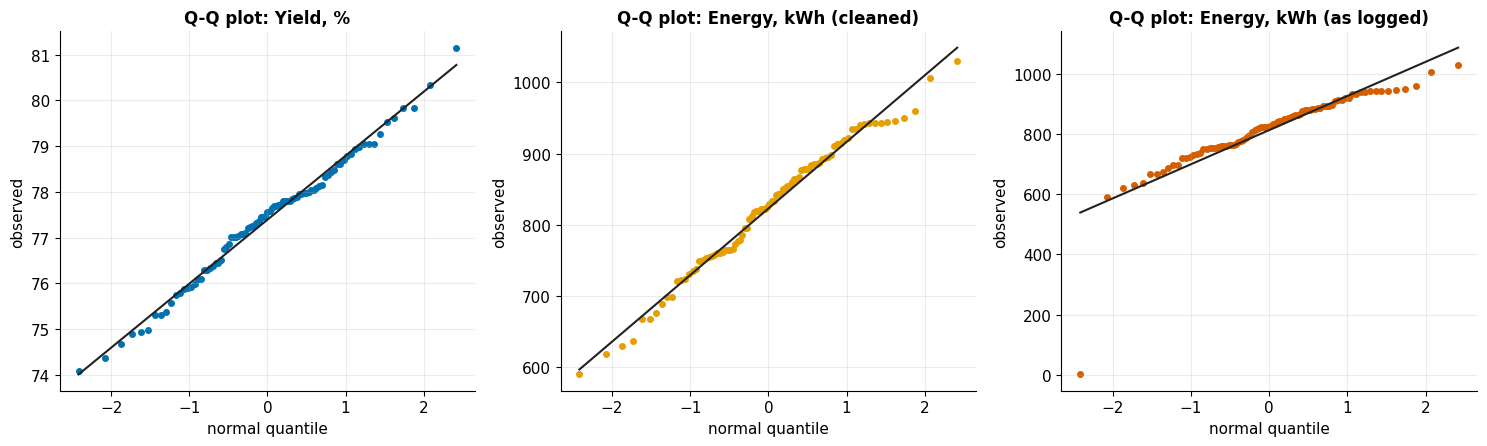

In [8]:
def normality(s):
    s = pd.Series(s).dropna()
    sw = stats.shapiro(s)
    ad = stats.anderson(s, dist="norm", method="interpolate")
    return {"n": len(s), "Shapiro-Wilk W": sw.statistic, "SW p": sw.pvalue,
            "Anderson-Darling A2": ad.statistic, "AD p (table, capped at 0.15)": ad.pvalue}


energy_as_logged = raw.drop_duplicates()["energy_kwh"].map(lambda t: parse_number(t)[0])
norm_table = pd.DataFrame({"yield %": normality(daily["yield_pct"]),
                           "energy kWh, cleaned": normality(daily["energy_kwh"]),
                           "energy kWh, as logged": normality(energy_as_logged)}).T
print(norm_table.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (label, s, col) in zip(ax, [("Yield, %", daily["yield_pct"], C["yield"]),
                                   ("Energy, kWh (cleaned)", daily["energy_kwh"], C["energy"]),
                                   ("Energy, kWh (as logged)", energy_as_logged, C["alarm"])]):
    (osm, osr), (slope, icept, _) = stats.probplot(s.dropna(), dist="norm")
    a.scatter(osm, osr, s=16, color=col)
    a.plot(osm, icept + slope * osm, color=C["limit"], lw=1.5)
    a.set(title=f"Q-Q plot: {label}", xlabel="normal quantile", ylabel="observed")
fig.tight_layout()
plt.show()

Neither test rejects normality for yield (Shapiro-Wilk W = 0.991, p = 0.80;
Anderson-Darling A² = 0.37, p above the table's 0.15 cap), and the Q-Q points lie on the
line, tails included. Cleaned energy passes as well (Shapiro-Wilk p = 0.38).

Energy as logged fails badly (Shapiro-Wilk p = 5.3e-10), and its Q-Q plot shows
why: one point, the MWh entry, sits far below the line. A failed normality test is often a
data-quality finding before it is a statistical one, and the right response here is to fix
the entry, not to transform the data.

### What non-normality would do to the limits

Normal 3-sigma limits leave
0.27 % of in-control points outside by chance. Fitting a skew-normal distribution to the
yield data, which allows for the slight skew the sample shows, puts the rate beyond the
mean ± 3 standard deviations at 0.29 %: about one false alarm in
345 days instead of one in 370. Percentile limits taken from the same fit
(the 0.135 and 99.865 percentiles) are 73.04 and 81.33 %, against
73.25 and 81.53 % from mean ± 3 SD: both about 0.2 of a point lower,
a small fraction of a sigma. The normal limits stand.

Had the tests failed for a reason that was not a data error (a skewed yield from drying
losses that cannot go below zero, say), three routes are open: a Box-Cox or Johnson
transformation, then limits on the transformed scale; percentile limits from a fitted
distribution, as above; or a non-parametric chart (a run chart with run rules, or limits
from the empirical 0.135 and 99.865 percentiles once there are several hundred points).
A caution on power: with 89 points Shapiro-Wilk would miss a mild skew, so the
Q-Q plot's tails are read as well as the p-value.

In [9]:
sn = stats.skewnorm(*stats.skewnorm.fit(daily["yield_pct"].dropna()))
m, s = daily["yield_pct"].mean(), daily["yield_pct"].std()
fa_rate = sn.cdf(m - 3 * s) + sn.sf(m + 3 * s)
pct_limits = sn.ppf([0.00135, 0.99865])
print(f"False-alarm rate beyond mean ± 3 SD under the skew-normal fit: {100 * fa_rate:.2f} %"
      f" (normal: 0.27 %)")
print(f"Percentile limits: {pct_limits[0]:.2f} to {pct_limits[1]:.2f} %;"
      f" mean ± 3 SD: {m - 3 * s:.2f} to {m + 3 * s:.2f} %")

False-alarm rate beyond mean ± 3 SD under the skew-normal fit: 0.29 % (normal: 0.27 %)
Percentile limits: 73.04 to 81.33 %; mean ± 3 SD: 73.25 to 81.53 %


## 5. Control charts

The yield data comes one value a day, so the natural chart is Individuals and Moving Range
(I-MR). Its limits come from the average moving range between consecutive days:

- sigma (within) = MR-bar / d2, with d2 = 1.128 for ranges of two
- I chart: CL = mean, UCL/LCL = CL ± 3 sigma, with zones at 1 and 2 sigma
- MR chart: CL = MR-bar, UCL = D4 × MR-bar with D4 = 3.267, LCL = 0

The brief also asks for X-bar/R on subgrouped data. There is no subgroup in a daily record,
so the days are grouped into consecutive 5-day blocks. That is a rational subgroup
only in the weak sense that days close together share weather and crew rotation; the
range inside a block includes day-to-day change that a true subgroup (five bottles off the
filler in a minute) would not, so the X-bar chart here is less sensitive than the
Port Louis one would be. It is built to show the method, and the I-MR chart is the one the
plant should run.

The limits are calculated here from the constants, not taken from an SPC package, and the
functions take any series, so the same code would run on a 1-second sensor feed.

### Which days to fit the limits on

Limits should describe the process while it is in
control. The first 30 days are the phase I window: the limits are fitted on
them and then applied to all 90. A second set fitted on every day is calculated for
comparison.

In [10]:
D2 = {2: 1.128, 3: 1.693, 4: 2.059, 5: 2.326, 6: 2.534}
D3 = {2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0}
D4 = {2: 3.267, 3: 2.574, 4: 2.282, 5: 2.114, 6: 2.004}
A2 = {2: 1.880, 3: 1.023, 4: 0.729, 5: 0.577, 6: 0.483}


def imr_limits(x):
    """I-MR limits from a series. Missing days are skipped; the moving range joins the
    values either side of a gap."""
    x = pd.Series(x, dtype=float).dropna()
    mr_bar = x.diff().abs().mean()
    sigma = mr_bar / D2[2]
    cl = x.mean()
    return {"n": len(x), "cl": cl, "sigma": sigma, "ucl": cl + 3 * sigma,
            "lcl": cl - 3 * sigma, "mr_bar": mr_bar, "mr_ucl": D4[2] * mr_bar}


def rule_signals(x, cl, sigma):
    """Positions breaking Western Electric rules: 1 beyond 3 sigma; 2 of 3 beyond 2 sigma,
    same side; 4 of 5 beyond 1 sigma, same side; 8 in a row on one side."""
    x = np.asarray(x, dtype=float)
    pos = np.flatnonzero(~np.isnan(x))
    z = (x[pos] - cl) / sigma
    out = {1: set(), 2: set(), 3: set(), 4: set()}
    for j in range(len(z)):
        if abs(z[j]) > 3:
            out[1].add(pos[j])
        for side in (1, -1):
            if j >= 2 and (side * z[j - 2:j + 1] > 2).sum() >= 2:
                out[2].add(pos[j])
            if j >= 4 and (side * z[j - 4:j + 1] > 1).sum() >= 4:
                out[3].add(pos[j])
            if j >= 7 and (side * z[j - 7:j + 1] > 0).all():
                out[4].add(pos[j])
    return {rule: sorted(int(p) for p in v) for rule, v in out.items()}


def plot_imr(ax_i, ax_mr, dates, x, lim, label, colour, fitted_on=None):
    x = pd.Series(np.asarray(x, dtype=float), index=dates)
    for k, alpha in ((3, 0.06), (2, 0.08), (1, 0.10)):
        ax_i.axhspan(lim["cl"] - k * lim["sigma"], lim["cl"] + k * lim["sigma"],
                     color=C["zone"], alpha=alpha, lw=0)
    ax_i.plot(x.index, x.values, "o-", color=colour, ms=3.5, lw=1)
    for v, name in ((lim["ucl"], "UCL"), (lim["cl"], "CL"), (lim["lcl"], "LCL")):
        ax_i.axhline(v, color=C["limit"], ls="-" if name == "CL" else "--", lw=1.2)
        ax_i.annotate(f"{name} {v:.2f}", (1.0, v), xycoords=("axes fraction", "data"),
                      xytext=(6, 0), textcoords="offset points", va="center", fontsize=10,
                      annotation_clip=False)
    flagged = sorted(set().union(*rule_signals(x.values, lim["cl"], lim["sigma"]).values()))
    if flagged:
        ax_i.plot(x.index[flagged], x.values[flagged], "s", color=C["alarm"], ms=8,
                  mfc="none", mew=2, label="rule broken")
        ax_i.legend(loc="lower left", fontsize=9)
    if fitted_on is not None:
        ax_i.axvspan(x.index[0], x.index[fitted_on - 1], color=C["muted"], alpha=0.15, lw=0)
        ax_i.annotate("phase I: limits fitted here", (x.index[0], lim["lcl"]), xytext=(4, 6),
                      textcoords="offset points", fontsize=10, color="#444444")
    ax_i.set(title=f"Individuals: {label}", ylabel=label)
    mr = x.dropna().diff().abs()
    ax_mr.plot(mr.index, mr.values, "o-", color=colour, ms=3, lw=1)
    high = mr[mr > lim["mr_ucl"]]
    ax_mr.plot(high.index, high.values, "s", color=C["alarm"], ms=8, mfc="none", mew=2)
    ax_mr.axhline(lim["mr_bar"], color=C["limit"], lw=1.2)
    ax_mr.axhline(lim["mr_ucl"], color=C["limit"], ls="--", lw=1.2)
    ax_mr.annotate(f"UCL {lim['mr_ucl']:.2f}", (1.0, lim["mr_ucl"]),
                   xycoords=("axes fraction", "data"), xytext=(6, 0), textcoords="offset points",
                   va="center", fontsize=10, annotation_clip=False)
    ax_mr.set(title="Moving range", ylabel="MR")
    ax_mr.tick_params(axis="x", rotation=30)

Moving range above its limit on 24 Aug: 5.36 points, from 75.79 to 81.15 %


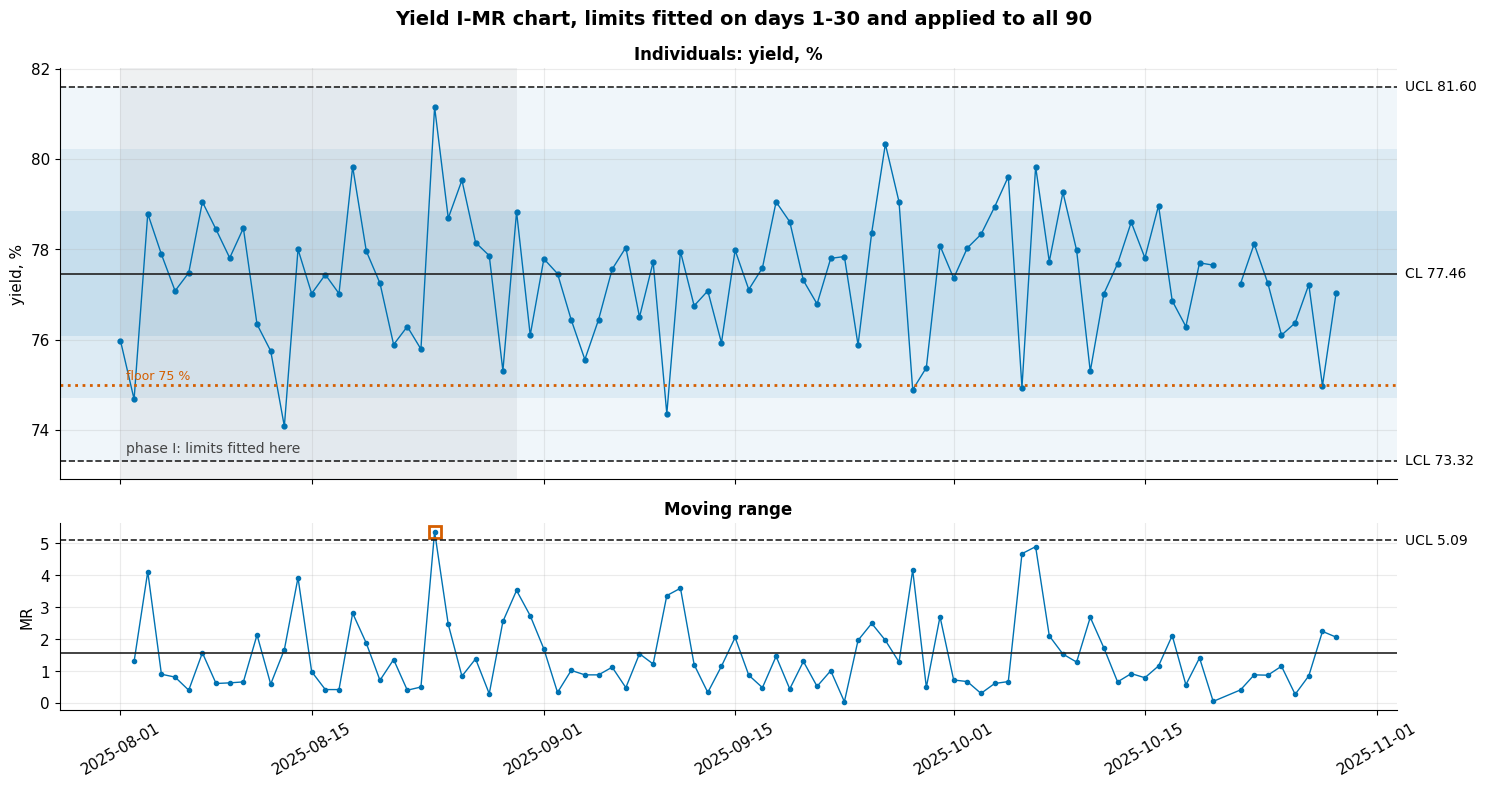

,CL,sigma,LCL,UCL,MR-bar,MR UCL,rule 1 days,rule 2 days,rule 3 days,rule 4 days,MR above UCL
fit,,,,,,,,,,,
"phase I, days 1-30",77.462,1.381,73.319,81.604,1.558,5.089,0,0,0,0,1
all 90 days,77.391,1.291,73.518,81.264,1.456,4.757,0,0,0,0,2


In [11]:
yv = daily["yield_pct"].values
fits = {"phase I, days 1-30": imr_limits(yv[:BASELINE_DAYS]), "all 90 days": imr_limits(yv)}
rows = []
for name, lim in fits.items():
    sig = rule_signals(yv, lim["cl"], lim["sigma"])
    mr_all = daily["yield_pct"].dropna().diff().abs()
    rows.append({"fit": name, "CL": lim["cl"], "sigma": lim["sigma"], "LCL": lim["lcl"],
                 "UCL": lim["ucl"], "MR-bar": lim["mr_bar"], "MR UCL": lim["mr_ucl"],
                 **{f"rule {r} days": len(v) for r, v in sig.items()},
                 "MR above UCL": int((mr_all > lim["mr_ucl"]).sum())})
fit_table = pd.DataFrame(rows).set_index("fit").round(3)
base = fits["phase I, days 1-30"]
mr_all = daily["yield_pct"].dropna().diff().abs()
mr_high = mr_all[mr_all > base["mr_ucl"]]
for i, v in mr_high.items():
    print(f"Moving range above its limit on {daily.at[i, 'date']:%d %b}: {v:.2f} points, "
          f"from {daily['yield_pct'].dropna().shift().at[i]:.2f} to {daily.at[i, 'yield_pct']:.2f} %")

fig, ax = plt.subplots(2, 1, figsize=(15, 8), sharex=True, height_ratios=[2.2, 1])
plot_imr(ax[0], ax[1], daily["date"], yv, base, "yield, %", C["yield"], fitted_on=BASELINE_DAYS)
ax[0].axhline(LSL, color=C["spec"], ls=":", lw=2)
ax[0].annotate(f"floor {LSL:.0f} %", (daily["date"].iloc[0], LSL), xytext=(4, 4),
               textcoords="offset points", color=C["spec"], fontsize=9)
fig.suptitle("Yield I-MR chart, limits fitted on days 1-30 and applied to all 90",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()
fit_table

### Reading the chart

With limits fitted on days 1 to 30 the centre line is
77.46 % and the limits are 73.32 to 81.60 %. Applied to all 90
days, no point falls outside them and none of the four run rules fires.

The moving-range chart flags one point: the jump of 5.36 points from
75.79 % to 81.15 % on 24 August 2025, which is the best day of the
whole run. A signal is a question, not a verdict, and the question here is what went
right that day; the shift return records nothing unusual. It sits inside the phase I window,
so the textbook step is to find its cause and, if one is found, refit the limits without it.
With no cause on record it stays in, and since it is an unusually good day it carries no
risk to the floor.

Yield at Dar es Salaam is in statistical control: the bad days are part of how the process
normally behaves, not interruptions to it. That is the more uncomfortable finding,
because a special cause can be found and removed, while common-cause spread needs the
process itself changed.

### Which fit to keep

The all-days fit gives 77.39 % and 73.52 to
81.26 %, no limit more than 0.34 of a point from the phase I set, because this
run holds steady from start to finish. The phase I limits are kept anyway, for the reason that
matters on a line that does move. Limits fitted on every day absorb whatever happens later:
if the dryer fouled in the last month, its lower yields would pull the centre line down
and widen the sigma, the drift would stop tripping the limits, and the quiet opening
weeks would start to look like the outliers. A frozen phase I baseline, refitted only after
a deliberate process change, is what lets a chart notice change at all. On the Port Louis
temperature run the two fits would part company; here they agree, and saying so is part
of the result.

The yield floor of 75 % is drawn on the chart for orientation only. It sits above the
lower control limit, inside the band the process covers on an ordinary day, which is why
the plant has floor breaches with no control signal.

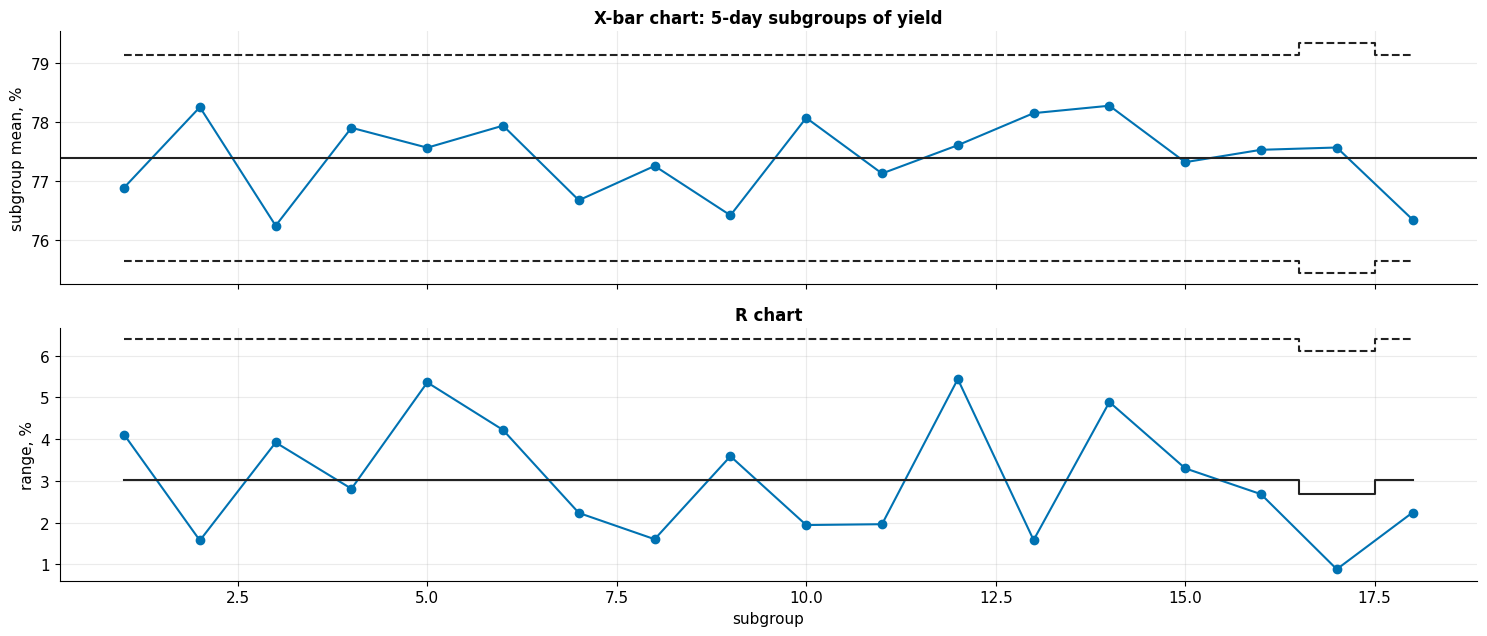

18 subgroups (sizes [4, 5]); grand mean 77.39 %, sigma from R-bar/d2 1.300
Subgroups outside X-bar limits: 0; outside R limits: 0


In [12]:
def xbar_r(x, n):
    """X-bar/R statistics for consecutive blocks of n days. Blocks with missing days keep
    the days they have; their limits use the constants for that block size."""
    x = pd.Series(np.asarray(x, dtype=float))
    groups = [g.dropna() for _, g in x.groupby(np.arange(len(x)) // n)]
    groups = [g for g in groups if len(g) >= 2]
    sizes = np.array([len(g) for g in groups])
    means = np.array([g.mean() for g in groups])
    ranges = np.array([g.max() - g.min() for g in groups])
    sigma = np.mean(ranges / np.array([D2[k] for k in sizes]))
    grand = np.concatenate([g.values for g in groups]).mean()
    return {"sizes": sizes, "means": means, "ranges": ranges, "sigma": sigma, "grand": grand,
            "x_ucl": grand + 3 * sigma / np.sqrt(sizes), "x_lcl": grand - 3 * sigma / np.sqrt(sizes),
            "r_cl": np.array([D2[k] for k in sizes]) * sigma,
            "r_ucl": np.array([D4[k] * D2[k] for k in sizes]) * sigma}


xr = xbar_r(yv, SUBGROUP_N)
k = np.arange(1, len(xr["means"]) + 1)
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)
ax[0].plot(k, xr["means"], "o-", color=C["yield"])
ax[0].step(k, xr["x_ucl"], where="mid", color=C["limit"], ls="--")
ax[0].step(k, xr["x_lcl"], where="mid", color=C["limit"], ls="--")
ax[0].axhline(xr["grand"], color=C["limit"])
ax[0].set(title=f"X-bar chart: {SUBGROUP_N}-day subgroups of yield", ylabel="subgroup mean, %")
ax[1].plot(k, xr["ranges"], "o-", color=C["yield"])
ax[1].step(k, xr["r_ucl"], where="mid", color=C["limit"], ls="--")
ax[1].step(k, xr["r_cl"], where="mid", color=C["limit"])
ax[1].set(title="R chart", xlabel="subgroup", ylabel="range, %")
fig.tight_layout()
plt.show()
out_x = int(((xr["means"] > xr["x_ucl"]) | (xr["means"] < xr["x_lcl"])).sum())
out_r = int((xr["ranges"] > xr["r_ucl"]).sum())
print(f"{len(k)} subgroups (sizes {sorted(set(xr['sizes'].tolist()))}); grand mean "
      f"{xr['grand']:.2f} %, sigma from R-bar/d2 {xr['sigma']:.3f}")
print(f"Subgroups outside X-bar limits: {out_x}; outside R limits: {out_r}")

The X-bar/R chart agrees: 18 subgroups, a grand mean of 77.39 % and a
within-subgroup sigma of 1.300, and no subgroup mean or range outside its
limits. The one subgroup with a missing day has four values and
slightly wider limits, which is why the limit lines step. Its sigma is close to the I-MR
sigma, as it should be when the days are independent.

The energy meter is the plant's nearest thing to a sensor channel, so it gets an I-MR
chart too, on the cleaned values.

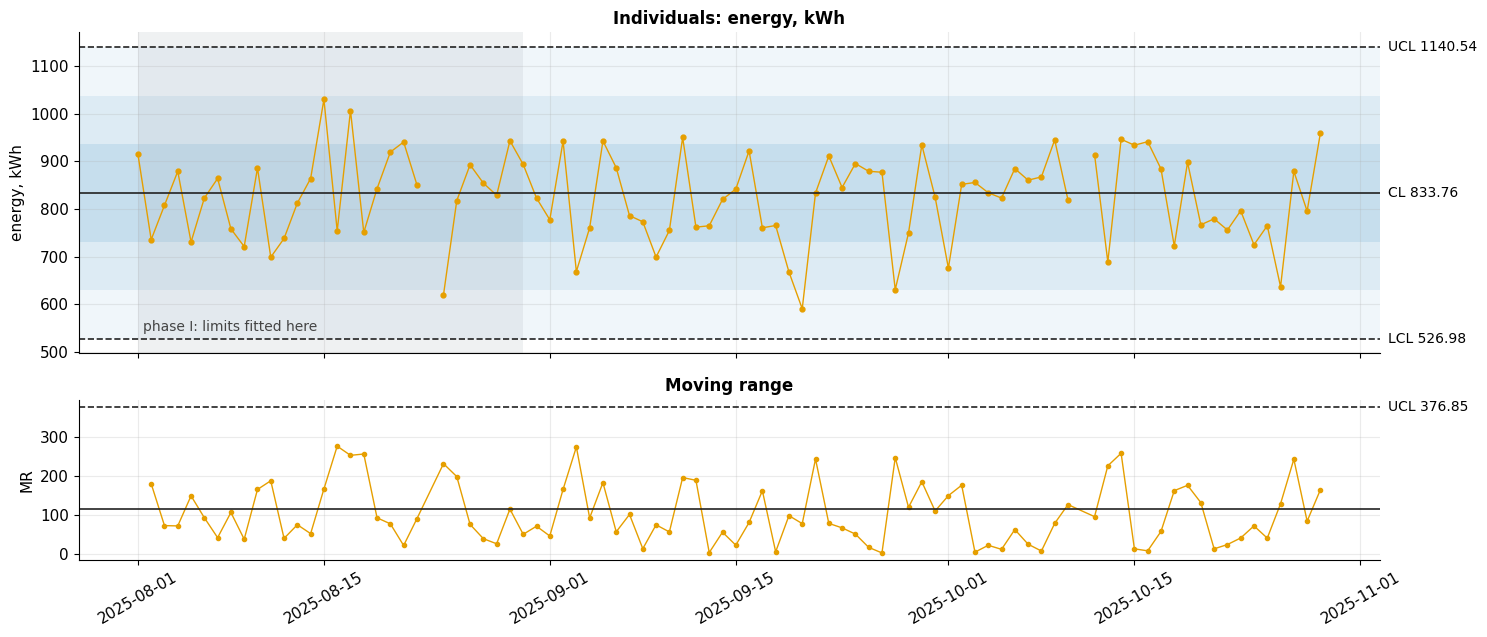

Energy days breaking a run rule: none
Energy sigma, cleaned days 1-60: 95.6 kWh; as logged days 1-60: 118.9 kWh


In [13]:
ev = daily["energy_kwh"].values
e_lim = imr_limits(ev[:BASELINE_DAYS])
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, height_ratios=[2, 1])
plot_imr(ax[0], ax[1], daily["date"], ev, e_lim, "energy, kWh", C["energy"], fitted_on=BASELINE_DAYS)
fig.tight_layout()
plt.show()
e_sig = rule_signals(ev, e_lim["cl"], e_lim["sigma"])
broken = {f"rule {r}": [str(daily['date'][p].date()) for p in v] for r, v in e_sig.items() if v}
print("Energy days breaking a run rule:", broken or "none")
raw_lim = imr_limits(energy_as_logged.values[:BASELINE_DAYS + 30])
print(f"Energy sigma, cleaned days 1-60: {imr_limits(ev[:60])['sigma']:.1f} kWh; "
      f"as logged days 1-60: {raw_lim['sigma']:.1f} kWh")

Energy use is in control: no point is outside the limits and no run rule fires. The last
line shows why cleaning comes before charting. Over the first 60 days, which include the
MWh entry, the moving-range sigma as logged is 119 kWh against
96 kWh cleaned. One bad entry makes two moving ranges of some 800 kWh
each, the limits widen by about a quarter, and a real rise in energy use of that size
would then pass the chart unseen.

## 6. Capability

The specification is one-sided: yield must be at least 75 %, and there is no upper
limit because more yield is never a defect. That decides which indices exist.

Cp and Pp compare the width of the specification with the spread of the process. With
only a lower limit there is no width, so neither index is defined, and software that
prints a Cp here has quietly invented an upper limit. Cpk reduces to
Cpl = (mean - LSL) / (3 × sigma within), with sigma within from the moving range: how
capable the process is when nothing but day-to-day noise is acting. Ppk reduces to
Ppl = (mean - LSL) / (3 × sigma overall), with the ordinary standard deviation: how the
process actually performed across the 90 days.

Confidence intervals use Bissell's approximation, Cpk ± 1.96 × sqrt(1/(9n) + Cpk²/(2(n-1))).

In [14]:
def capability(x, lsl, sigma_within, usl=None, z=1.96):
    x = pd.Series(x, dtype=float).dropna()
    n, mean, s = len(x), x.mean(), x.std(ddof=1)
    out = {"n": n, "mean": mean, "sigma within": sigma_within, "sigma overall": s,
           "Cp": np.nan, "Pp": np.nan}
    if usl is not None:
        out["Cp"] = (usl - lsl) / (6 * sigma_within)
        out["Pp"] = (usl - lsl) / (6 * s)
    out["Cpk"] = (mean - lsl) / (3 * sigma_within)
    out["Ppk"] = (mean - lsl) / (3 * s)
    for idx in ("Cpk", "Ppk"):
        half = z * np.sqrt(1 / (9 * n) + out[idx] ** 2 / (2 * (n - 1)))
        out[f"{idx} 95% CI"] = (out[idx] - half, out[idx] + half)
    out["ppm below, within"] = stats.norm.cdf((lsl - mean) / sigma_within) * 1e6
    out["ppm below, overall"] = stats.norm.cdf((lsl - mean) / s) * 1e6
    out["observed below"] = int((x < lsl).sum())
    return out


cap = capability(daily["yield_pct"], LSL, imr_limits(yv)["sigma"])
for key, val in cap.items():
    if isinstance(val, tuple):
        val = f"{val[0]:.3f} to {val[1]:.3f}"
    elif isinstance(val, float):
        val = f"{val:.3f}"
    print(f"{key:>22}: {val}")

                     n: 89
                  mean: 77.391
          sigma within: 1.291
         sigma overall: 1.380
                    Cp: nan
                    Pp: nan
                   Cpk: 0.617
                   Ppk: 0.577
            Cpk 95% CI: 0.503 to 0.732
            Ppk 95% CI: 0.468 to 0.687
     ppm below, within: 31998.313
    ppm below, overall: 41610.495
        observed below: 6


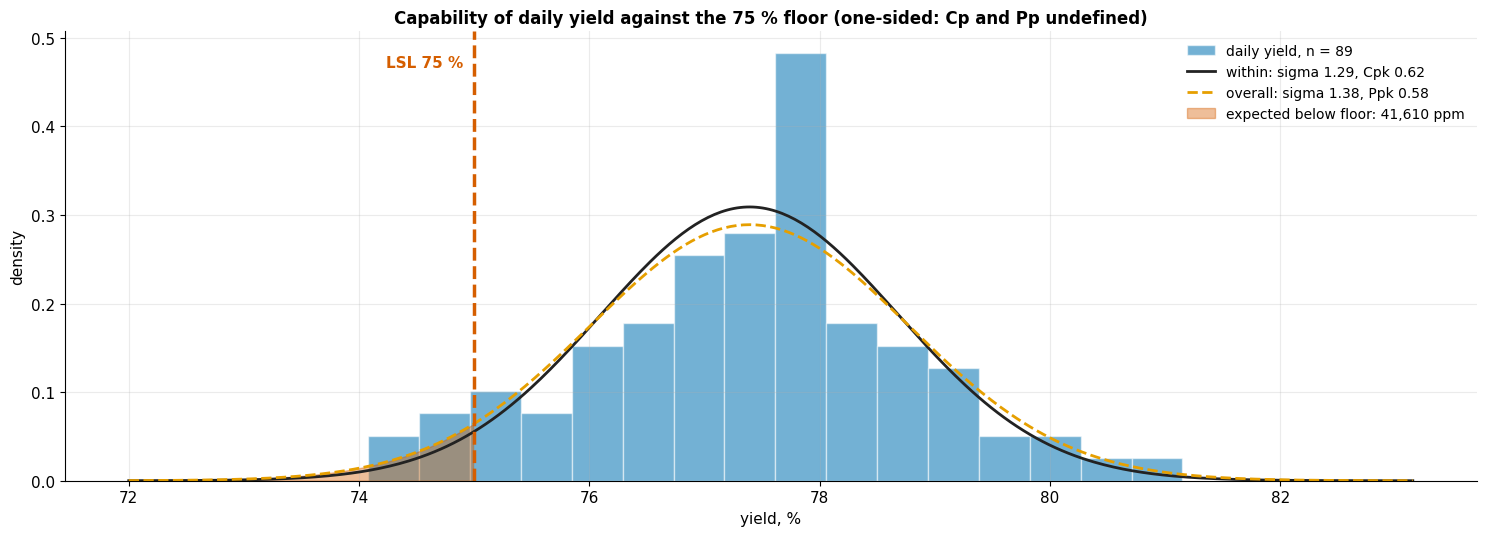

In [15]:
yy = daily["yield_pct"].dropna()
grid = np.linspace(LSL - 3, yy.max() + 2, 400)
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.hist(yy, bins=16, density=True, color=C["yield"], alpha=0.55, edgecolor="white",
        label=f"daily yield, n = {cap['n']}")
ax.plot(grid, stats.norm.pdf(grid, cap["mean"], cap["sigma within"]), color=C["limit"], lw=2,
        label=f"within: sigma {cap['sigma within']:.2f}, Cpk {cap['Cpk']:.2f}")
ax.plot(grid, stats.norm.pdf(grid, cap["mean"], cap["sigma overall"]), color=C["energy"], lw=2,
        ls="--", label=f"overall: sigma {cap['sigma overall']:.2f}, Ppk {cap['Ppk']:.2f}")
tail = grid[grid <= LSL]
ax.fill_between(tail, stats.norm.pdf(tail, cap["mean"], cap["sigma overall"]), color=C["alarm"],
                alpha=0.4, label=f"expected below floor: {cap['ppm below, overall']:,.0f} ppm")
ax.axvline(LSL, color=C["spec"], ls="--", lw=2.5)
ax.annotate(f"LSL {LSL:.0f} %", (LSL, ax.get_ylim()[1] * 0.92), xytext=(-8, 0),
            textcoords="offset points", ha="right", color=C["spec"], fontweight="bold")
ax.set(title="Capability of daily yield against the 75 % floor (one-sided: Cp and Pp undefined)",
       xlabel="yield, %", ylabel="density")
ax.legend(loc="upper right", fontsize=10)
fig.tight_layout()
plt.show()

| Index | Value | 95 % interval | Meaning for the line |
|---|---|---|---|
| Cp | not defined | | one-sided specification |
| Pp | not defined | | one-sided specification |
| Cpk | 0.62 | 0.50 to 0.73 | the floor is 1.85 within-sigma below the mean, not the 4 a Cpk of 1.33 needs |
| Ppk | 0.58 | 0.47 to 0.69 | actual performance over 90 days, a little worse than the within figure |

Sigma within, from the moving range, is 1.29 points; sigma overall is 1.38.

### What the numbers mean on the floor

A Cpk of 0.62 is far from capable. Even the top of
its confidence interval, 0.73, is below 1. Using the overall sigma, the normal
model expects about 41,600 below-floor days per million, which is
4.2 % of days or roughly one day in 24. The record is a little worse:
6 of 89 days (6.7 %) fell below 75 %, against
3.7 expected, a gap that chance covers easily at this sample size. Cpk and Ppk are close
because the process is stable; a large gap between them would have meant drift between
days that the within-sigma does not see.

For the quality manager the daily decision is simple to state. On any given day there is
about a one-in-24 chance the line finishes below the floor, and nothing on
the control chart will warn of it, because that day is ordinary for this process. Each
below-floor day is hibiscus calyx bought from farmer-members and lost in drying and
sieving, and more energy per kilogram of product, which is the plant's sustainability KPI.
Underdried or overdried calyx also arrives in Johannesburg as a problem for the Hibiscus
Pressure tablets.

### What it would take to reach Cpk 1.33

Either the mean rises to
80.15 % with the spread unchanged, or the within-sigma falls to
0.60 with the mean unchanged, about half of today's. The next cell asks how
far removing the heat effect found in section 3 would go.

In [16]:
known = daily.dropna(subset=["ambient_temp_c", "yield_pct"]).copy()
known["heat_excess"] = (known["ambient_temp_c"] - HOT_C).clip(lower=0)
fit = stats.linregress(known["heat_excess"], known["yield_pct"])
adjusted = daily["yield_pct"].copy()
heat = (daily["ambient_temp_c"] - HOT_C).clip(lower=0).fillna(0)
adjusted = adjusted - fit.slope * heat          # add back what each hot degree took
cap_adj = capability(adjusted, LSL, imr_limits(adjusted.values)["sigma"])
mean_needed = LSL + 3 * TARGET_CPK * cap["sigma within"]
sigma_needed = (cap["mean"] - LSL) / (3 * TARGET_CPK)
print(f"Yield loss per °C above {HOT_C:.0f} °C: {-fit.slope:.2f} points (r² = {fit.rvalue**2:.2f})")
print(f"With the heat loss removed: mean {cap_adj['mean']:.2f} %, sigma within "
      f"{cap_adj['sigma within']:.2f}, Cpk {cap_adj['Cpk']:.2f}, Ppk {cap_adj['Ppk']:.2f}, "
      f"expected {cap_adj['ppm below, overall']:,.0f} ppm below floor")
print(f"For Cpk {TARGET_CPK}: mean {mean_needed:.2f} % at today's sigma, or sigma "
      f"{sigma_needed:.2f} at today's mean")

Yield loss per °C above 25 °C: 0.52 points (r² = 0.34)
With the heat loss removed: mean 77.85 %, sigma within 1.10, Cpk 0.86, Ppk 0.83, expected 6,418 ppm below floor
For Cpk 1.33: mean 80.15 % at today's sigma, or sigma 0.60 at today's mean


Each degree above 25 °C costs about 0.52 points of yield. Adding that back
day by day raises the mean to 77.85 %, narrows the spread, and lifts Cpk from
0.62 to 0.86, with expected below-floor days falling to about
6,400 per million. That is a large step but not the whole way to 1.33:
the hall temperature is the biggest single lever, and the rest has to come from the
dryer itself. The projection assumes the relationship is causal and that cooling the
hall (or moving the drying load to the cooler hours) removes it; a short trial on hot
days would test that before money is spent.

Real-time capability monitoring follows directly. The same `capability()` function run
each night over the last 30 days gives a rolling Ppk, and a falling rolling Ppk is a
capability warning that arrives before the floor is breached often enough to notice.

## 7. Anomaly detection and early warning

The control chart answers "is today unusual?". An early warning has to answer a harder
question: "is the process starting to slide?". A dryer fouling, a burner losing
efficiency or a run of hot weather costs a little yield a day, and no single day looks
wrong. Two detectors are compared on that job, using the phase I mean
(77.46 %) and sigma (1.381) as the in-control reference.

The rolling z-score compares each day with the mean and standard deviation of the
previous 7 days and alarms when z falls below -c. The brief suggests a 60-sample window
for a 1-second series; 7 days is the daily equivalent of "the recent past".

The lower CUSUM keeps a running sum, C(t) = max(0, C(t-1) + (mu0 - k sigma) - x(t)), with
k = 0.5, so each day more than half a sigma below the reference adds to it and better days
drain it. It alarms when C exceeds h sigma, after which C resets.

Defaults are not accepted. The threshold for each is tuned by simulation: 2,000 in-control
90-day series drawn from the phase I normal model give the false-alarm rate, and the same
series with a fault injected from day 31 give the detection delay. Two faults are tested: a
slow decline of 0.1 points a day (fouling) and a sudden step of
2 sigma (a failed burner or a wrong setting).

In [17]:
def cusum_lower(x, mu, sigma, k=0.5, h=5.0):
    """Lower one-sided CUSUM over the last axis. Missing days leave C unchanged.
    Returns a boolean alarm array the same shape as x."""
    x = np.atleast_2d(np.asarray(x, dtype=float))
    c = np.zeros(x.shape[0])
    alarms = np.zeros(x.shape, dtype=bool)
    for t in range(x.shape[1]):
        xt = x[:, t]
        ok = ~np.isnan(xt)
        c[ok] = np.maximum(0.0, c[ok] + (mu - k * sigma) - xt[ok])
        hit = c > h * sigma
        alarms[:, t] = hit
        c[hit] = 0.0
    return alarms


def rolling_z(x, window=7, c=3.0):
    """Alarm when a day sits more than c standard deviations below the previous `window` days."""
    x = np.atleast_2d(np.asarray(x, dtype=float))
    alarms = np.zeros(x.shape, dtype=bool)
    for t in range(window, x.shape[1]):
        past = x[:, t - window:t]
        z = (x[:, t] - np.nanmean(past, axis=1)) / np.nanstd(past, axis=1, ddof=1)
        alarms[:, t] = z < -c
    return alarms


def first_alarm_after(alarms, onset):
    """Days from onset to the first alarm at or after it; NaN if none."""
    late = alarms[:, onset:]
    hit = late.any(axis=1)
    return np.where(hit, late.argmax(axis=1), np.nan)


MU0, SIGMA0 = base["cl"], base["sigma"]
N_SIM, DAYS, ONSET = 2000, 90, BASELINE_DAYS
DRIFT_PP_PER_DAY, STEP_SIGMA = 0.1, 2.0
rng = np.random.default_rng(SEED)
in_control = rng.normal(MU0, SIGMA0, size=(N_SIM, DAYS))
ramp = np.clip(np.arange(DAYS) - ONSET + 1, 0, None) * DRIFT_PP_PER_DAY
drifting = in_control - ramp
stepped = in_control - STEP_SIGMA * SIGMA0 * (np.arange(DAYS) >= ONSET)

detectors = {**{("CUSUM", h): (lambda x, h=h: cusum_lower(x, MU0, SIGMA0, 0.5, h))
                for h in (3.0, 4.0, 5.0, 6.0)},
             **{("rolling z", c): (lambda x, c=c: rolling_z(x, 7, c))
                for c in (2.5, 3.0, 4.0, 5.0)}}
rows = []
for (method, thr), detect in detectors.items():
    fa = detect(in_control).sum(axis=1).mean()
    d_drift = first_alarm_after(detect(drifting), ONSET)
    d_step = first_alarm_after(detect(stepped), ONSET)
    rows.append({"method": method, "threshold": thr, "false alarms per 90 days": fa,
                 "drift: median delay, days": np.median(np.nan_to_num(d_drift, nan=np.inf)),
                 "drift: caught within 30 days": np.mean(d_drift <= 30),
                 "step: median delay, days": np.median(np.nan_to_num(d_step, nan=np.inf)),
                 "step: caught within 7 days": np.mean(d_step <= 7)})
tuning = pd.DataFrame(rows).set_index(["method", "threshold"]).round(2)
tuning

false alarms per 90 days  drift: median delay, days  \
method    threshold                                                        
CUSUM     3.0                            0.72                       11.0   
          4.0                            0.24                       14.0   
          5.0                            0.08                       15.0   
          6.0                            0.03                       17.0   
rolling z 2.5                            2.39                       12.0   
          3.0                            1.27                       24.0   
          4.0                            0.39                        inf   
          5.0                            0.14                        inf   

                     drift: caught within 30 days  step: median delay, days  \
method    threshold                                                           
CUSUM     3.0                                1.00                       1.0   
          4.0                                1.00                       2.0   
          5.0                                1.00                       3.0   
          6.0                                1.00                       3.0   
rolling z 2.5                                0.84                       1.0   
          3.0                                0.58                      13.0   
          4.0                                0.22                       inf   
          5.0                                0.08                       inf   

                     step: caught within 7 days  
method    threshold                              
CUSUM     3.0                              1.00  
          4.0                              1.00  
          5.0                              1.00  
          6.0                              0.99  
rolling z 2.5                              0.67  
          3.0                              0.45  
          4.0                              0.18  
          5.0                              0.07

In [18]:
FA_BUDGET = 0.5      # at most one false alarm every six months or so

def pick(method):
    ok = tuning.loc[method]
    ok = ok[ok["false alarms per 90 days"] <= FA_BUDGET]
    return ok.index.min()      # the most sensitive threshold inside the budget

H, Z_C = pick("CUSUM"), pick("rolling z")
chosen = tuning.loc[[("CUSUM", H), ("rolling z", Z_C)]]
print(f"Chosen: CUSUM h = {H}, rolling z c = {Z_C}")
chosen

Chosen: CUSUM h = 4.0, rolling z c = 4.0


,,false alarms per 90 days,"drift: median delay, days",drift: caught within 30 days,"step: median delay, days",step: caught within 7 days
method,threshold,,,,,
CUSUM,4.0,0.24,14.0,1.00,2.0,1.00
rolling z,4.0,0.39,inf,0.22,inf,0.18


The tuning table is the evidence for the thresholds. Lower thresholds catch faults sooner
and cry wolf more often. With a budget of at most 0.5 false alarms per 90 days,
the CUSUM's best setting is h = 4 (0.24 false alarms per 90 days, about
one every 12 months) and the rolling z-score's is c = 4.0
(0.39 per 90 days).

At those settings the comparison is one-sided. Against the slow decline the CUSUM's median
delay is 14 days and it catches 100 % of declines within
30 days; the rolling z-score catches 22 %. The reason is in the method: a rolling window moves down with the drift,
so a slow slide never looks unusual against the last week, while the CUSUM keeps
comparing against the fixed baseline and adds up the small shortfalls. Against the sudden
step the CUSUM is faster too, catching 100 % within a week against
18 %. Sensitivity and specificity are traded on the same false-alarm budget,
and the CUSUM wins both.

The chosen CUSUM is now run on the real 90 days, and on a copy of them with a
0.1-point-a-day decline added from day 61, to see it work on this
plant's own noise.

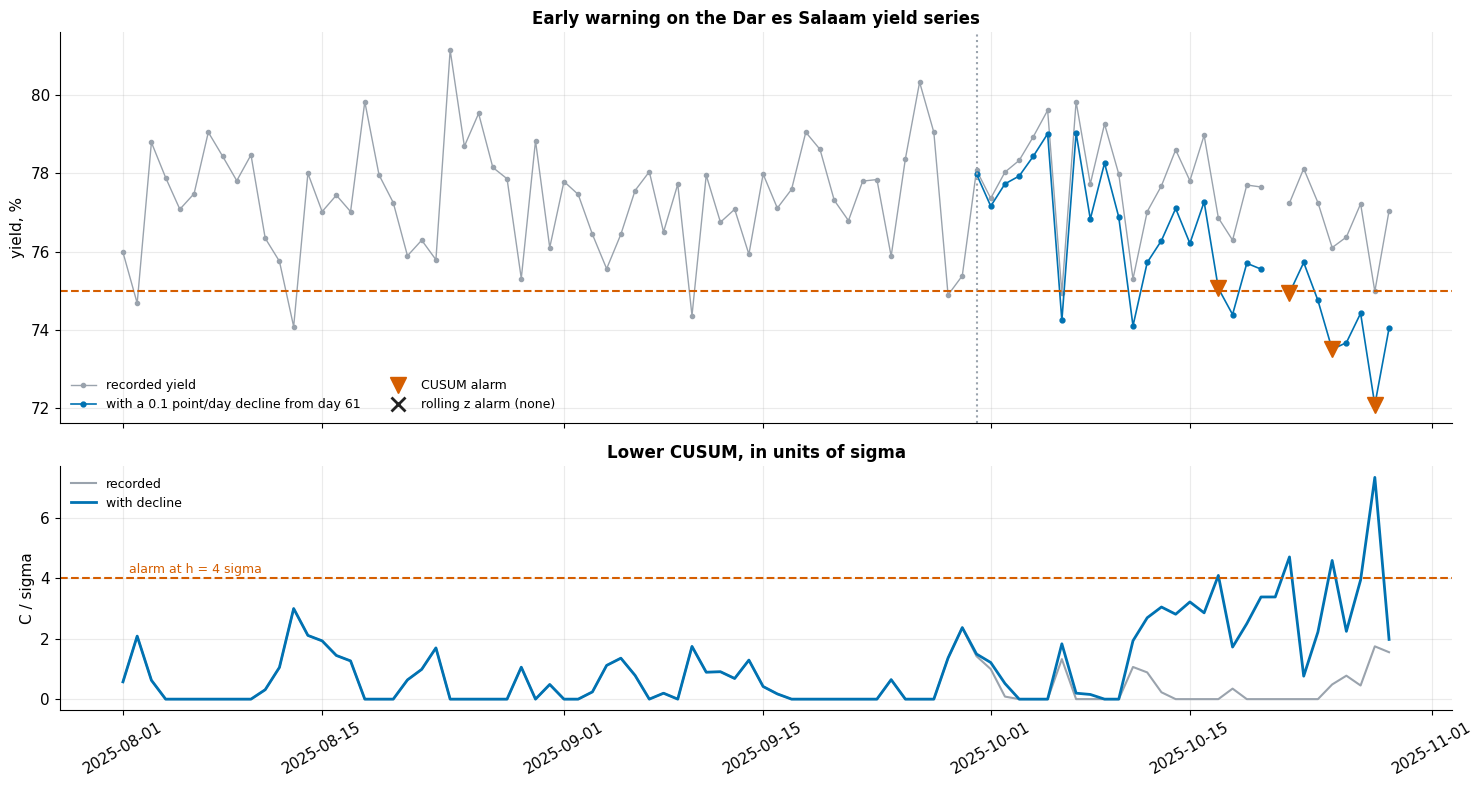

Alarms on the recorded series: 0
Days from decline start to first CUSUM alarm: 17; rolling z: None
Yield lost by then: 1.8 points


In [19]:
REAL_ONSET = 60      # index of day 61: the test decline starts two-thirds of the way in
real = cusum_lower(yv, MU0, SIGMA0, 0.5, H)[0]
fault =yv - np.clip(np.arange(len(yv)) - REAL_ONSET + 1, 0, None) * DRIFT_PP_PER_DAY
faulted = cusum_lower(fault, MU0, SIGMA0, 0.5, H)[0]
z_fault = rolling_z(fault, 7, Z_C)[0]
delay_real = int(np.argmax(faulted[REAL_ONSET:])) if faulted[REAL_ONSET:].any() else None
delay_z = int(np.argmax(z_fault[REAL_ONSET:])) if z_fault[REAL_ONSET:].any() else None


def cusum_path(x, mu, sigma, k, h):
    c, path = 0.0, []
    for v in x:
        if not np.isnan(v):
            c = max(0.0, c + (mu - k * sigma) - v)
        path.append(c)
        if c > h * sigma:
            c = 0.0
    return np.array(path) / sigma


fig, ax = plt.subplots(2, 1, figsize=(15, 8), sharex=True, height_ratios=[1.6, 1])
d = daily["date"]
ax[0].plot(d, yv, "o-", color=C["muted"], ms=3, lw=1, label="recorded yield")
ax[0].plot(d[REAL_ONSET:], fault[REAL_ONSET:], "o-", color=C["yield"], ms=3.5, lw=1.2,
           label=f"with a {DRIFT_PP_PER_DAY} point/day decline from day {REAL_ONSET + 1}")
ax[0].plot(d[faulted], fault[faulted], "v", color=C["alarm"], ms=12, label="CUSUM alarm")
ax[0].plot(d[z_fault], fault[z_fault], "x", color=C["limit"], ms=10, mew=2,
           label=f"rolling z alarm ({int(z_fault.sum()) or 'none'})")
ax[0].axhline(LSL, color=C["spec"], ls="--", lw=1.5)
ax[0].axvline(d[REAL_ONSET], color=C["muted"], ls=":", lw=1.5)
ax[0].set(title="Early warning on the Dar es Salaam yield series", ylabel="yield, %")
ax[0].legend(loc="lower left", fontsize=9, ncols=2)
ax[1].plot(d, cusum_path(yv, MU0, SIGMA0, 0.5, H), color=C["muted"], lw=1.5, label="recorded")
ax[1].plot(d, cusum_path(fault, MU0, SIGMA0, 0.5, H), color=C["yield"], lw=2, label="with decline")
ax[1].axhline(H, color=C["alarm"], ls="--", lw=1.5)
ax[1].annotate(f"alarm at h = {H:.0f} sigma", (d.iloc[0], H), xytext=(4, 4),
               textcoords="offset points", color=C["alarm"], fontsize=9)
ax[1].set(title="Lower CUSUM, in units of sigma", ylabel="C / sigma")
ax[1].legend(loc="upper left", fontsize=9)
ax[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()
print(f"Alarms on the recorded series: {int(real.sum())}")
print(f"Days from decline start to first CUSUM alarm: {delay_real}; rolling z: {delay_z}")
print(f"Yield lost by then: {DRIFT_PP_PER_DAY * (delay_real + 1):.1f} points")

On the recorded 90 days the CUSUM raises no alarm, as a stable process
should. On the copy with the decline it alarms 17 days after the decline
starts, when the daily loss has reached 1.8 points, well before most days fall
below the floor. The rolling z-score, at its tuned threshold, never alarms on the decline within the remaining 30 days.

### Sensor faults are a separate job

The CUSUM watches the process. The record also needs a
screen for bad readings, the MWh entry and the 320 °C reading of section 2,
before they reach the charts. Two screens are compared on the readings as logged: a robust
z-score per channel (distance from the median in units of 1.4826 × MAD, flag above 5) and an
isolation forest on all three channels together.

In [20]:
as_logged = raw.drop_duplicates().reset_index(drop=True)
readings = pd.DataFrame({c: as_logged[c].map(lambda t: parse_number(t)[0]) for c in NUMERIC})


def robust_z(s):
    med = s.median()
    return (s - med) / (1.4826 * (s - med).abs().median())


rz = readings.apply(robust_z).abs()
rz_flags = rz.index[(rz > 5).any(axis=1)].tolist()
complete = readings.dropna()
forest = IsolationForest(n_estimators=500, random_state=SEED).fit(complete)
score = pd.Series(forest.score_samples(complete), index=complete.index).sort_values()
gap = score.diff().iloc[1:6]
print("Robust z > 5 flags rows:", [i + 1 for i in rz_flags])
print("Lowest isolation-forest scores (row: score):",
      {int(i) + 1: round(v, 3) for i, v in score.head(5).items()})
print(readings.loc[rz_flags])

Robust z > 5 flags rows: [45, 59]
Lowest isolation-forest scores (row: score): {59: -0.769, 45: -0.718, 24: -0.628, 17: -0.551, 58: -0.533}
    ambient_temp_c  energy_kwh  yield_pct
44            29.5        0.82      75.93
58           320.0      749.70      74.89


Both screens flag the same 2 rows, the two faults found by hand in section 2,
and nothing else. The isolation forest ranks the same two rows as its most anomalous, but
its scores fall away gradually after them (-0.718 for the second, -0.628
for the third), so it would need a cut-off chosen by hand. The robust z-score separates them by a wide
margin: the faults score at least 8, every other reading at most 3.0. The robust z-score is the one to deploy: it needs no training, it is
explainable to the person typing the return ("this number is five times further from
normal than anything else you have entered"), and it can run as an Excel data-validation
rule at the moment of entry, which is the earliest warning there is.

### Deployment

At Dar es Salaam the data arrives once a day, so the latency is one shift:
a scheduled script that reads the day's return, runs the entry screen, appends the
reading, updates the CUSUM and the rolling Ppk, and emails the shift lead takes well under
a second of computing. The same functions take a 1-second sensor stream unchanged; at that
rate the CUSUM is still a single addition per reading, light enough for an edge gateway.
The cost to watch is not computing but alarm fatigue, which is why the threshold was tuned
against a false-alarm budget.

### Alerting framework

Three levels, each tied to what is at stake:

| Level | Trigger | Who | Action |
|---|---|---|---|
| Watch | CUSUM above half its alarm level, or a reading flagged by the entry screen | shift lead | check the reading; look at dryer exhaust and hall temperature |
| Act | CUSUM alarm (h = 4) or any day outside the I-chart limits | process engineer, same day | inspect the dryer (fouling, burner, airflow); check calyx moisture in and out |
| Hold | a day below the 75 % floor during an Act alarm | quality manager | hold the day's product for moisture and microbial checks before it ships to Johannesburg |

## 8. Recommendations for the Dar es Salaam quality manager

Written for someone who has not studied statistics.

1. The line is steady, but it runs too close to the floor. Most days the yield is fine,
   but about one day in 24 it drops below 75 %, and that is normal
   behaviour for the line as it runs today, not bad luck. Checking harder will not fix it.
   Changing the process will.
2. Tackle the heat first. Days hotter than 25 °C in the hall lose about
   0.52 points of yield for every extra degree. Try moving drying to the cooler
   hours, or improving hall ventilation, for two weeks of hot days, and compare yield with
   the same weeks before.
3. Find out what shift A does differently. On shift A, more energy seems to go with more
   yield; on the other shifts it does not. The evidence is not yet strong. Watch a shift A
   dryer run, write down its settings, and try them on another shift for a fortnight.
   If it is a longer or slower dry, it may be worth making standard.
4. Fix the shift return at the point of entry. About one row in 6 of the
   record had something wrong with it. Make the Excel return accept only numbers in the
   number columns, pick the shift from a list, fill the date automatically, and warn when a
   value is far from normal.
5. Turn on the automatic early warning. Run the CUSUM each morning on yesterday's yield.
   It would have caught a slow decline of 0.1 points a day within about
   14 days, and it should raise a false alarm only about once in
   12 months. Use the three levels above, so everyone knows who acts.
6. Measure it again in 30 days. Recalculate Cpk after each change. The aim is
   1.33; today it is 0.62.

### What automated monitoring gives the plant that the paper and Excel returns did not

The returns recorded every number and nobody read them. The monitoring reads every one,
the day it arrives. It catches slow decline that no one would notice day to day, it stops
a typing error from corrupting a month of averages, and it keeps an audit trail of every
correction. The next step is a temperature and humidity sensor on the dryer exhaust and in
the hall, logging every minute, so the warning comes during the shift rather than after it.

## 9. Figures used in this narrative

Every number in the markdown above is filled in from this dictionary when the notebook is
built, and the build fails if the kernel's values differ from the ones in the text.

In [21]:
energy_raw_sigma = raw_lim["sigma"]
cus, rz_ = tuning.loc[("CUSUM", H)], tuning.loc[("rolling z", Z_C)]
fa_rate_pct = 100 * fa_rate
FIGURES = {
    "raw_rows": len(raw), "duplicate_rows": int(raw.duplicated().sum()),
    "n_issue_cells": len(issues), "n_issue_rows": int(issues["row"].nunique()),
    "energy_fault_logged": float(readings["energy_kwh"].min()),
    "ambient_fault_c": float(readings["ambient_temp_c"].max()),
    "days": len(daily), "yield_days": int(daily["yield_pct"].notna().sum()),
    "lsl": LSL, "hot_c": HOT_C, "baseline_days": BASELINE_DAYS, "subgroup_n": SUBGROUP_N,
    "target_cpk": TARGET_CPK, "target_z": round(3 * TARGET_CPK, 0),
    "yield_mean": round(cap["mean"], 2), "yield_median": round(daily["yield_pct"].median(), 2),
    "yield_sd": round(cap["sigma overall"], 2), "yield_min": round(yy.min(), 2),
    "yield_max": round(yy.max(), 2), "yield_skew": round(yy.skew(), 2),
    "yield_kurt": round(yy.kurt(), 2),
    "gap_sd": round((cap["mean"] - LSL) / cap["sigma overall"], 1),
    "energy_mean": round(daily["energy_kwh"].mean(), 0),
    "energy_sd": round(daily["energy_kwh"].std(), 0),
    "r_ambient_yield": round(corr.loc["ambient_temp_c", "yield_pct"], 2),
    "r_energy_yield": round(corr.loc["energy_kwh", "yield_pct"], 2),
    "r_shift_a": round(r_a.statistic, 2), "p_shift_a": round(r_a.pvalue, 3),
    "n_shift_a": int((both["shift"] == "A").sum()),
    "r_shift_bc": round(r_bc.statistic, 2),
    "yield_hot_mean": round(hot_y.mean(), 2), "yield_cool_mean": round(cool_y.mean(), 2),
    "hot_loss": round(cool_y.mean() - hot_y.mean(), 2), "p_hot": round(t_hot.pvalue, 5),
    "p_shift_anova": round(f_shift.pvalue, 2), "acf1": round(acf1, 2),
    "sw_w": round(norm_table.loc["yield %", "Shapiro-Wilk W"], 3),
    "sw_p": round(norm_table.loc["yield %", "SW p"], 2),
    "ad_a2": round(norm_table.loc["yield %", "Anderson-Darling A2"], 2),
    "sw_p_energy": round(norm_table.loc["energy kWh, cleaned", "SW p"], 2),
    "sw_p_energy_raw": float(f"{norm_table.loc['energy kWh, as logged', 'SW p']:.1e}"),
    "fa_rate_skewnorm": round(fa_rate_pct, 2), "fa_one_in": round(100 / fa_rate_pct, 0),
    "pct_lcl": round(pct_limits[0], 2), "pct_ucl": round(pct_limits[1], 2),
    "sd3_lcl": round(m - 3 * s, 2), "sd3_ucl": round(m + 3 * s, 2),
    "pct_shift": round(np.mean([m - 3 * s - pct_limits[0], m + 3 * s - pct_limits[1]]), 1),
    "base_cl": round(base["cl"], 2), "base_lcl": round(base["lcl"], 2),
    "base_ucl": round(base["ucl"], 2), "base_sigma": round(base["sigma"], 3),
    "base_signals": int(fit_table.loc["phase I, days 1-30"].filter(like="rule").sum()),
    "mr_out": len(mr_high), "mr_out_value": round(mr_high.iloc[0], 2),
    "mr_out_yield": round(daily.at[mr_high.index[0], "yield_pct"], 2),
    "mr_out_from": round(daily["yield_pct"].dropna().shift().at[mr_high.index[0]], 2),
    "mr_out_date": f"{daily.at[mr_high.index[0], 'date']:%d %B %Y}".lstrip("0"),
    "base_mr_ucl": round(base["mr_ucl"], 2),
    "all_cl": round(fits["all 90 days"]["cl"], 2), "all_lcl": round(fits["all 90 days"]["lcl"], 2),
    "all_ucl": round(fits["all 90 days"]["ucl"], 2),
    "fit_gap": round(max(abs(fits["all 90 days"][k] - base[k]) for k in ("cl", "lcl", "ucl")), 2),
    "n_subgroups": len(xr["means"]), "xbar_grand": round(xr["grand"], 2),
    "xbar_sigma": round(xr["sigma"], 3), "xbar_out": out_x, "r_out": out_r,
    "energy_signals": len(set().union(*e_sig.values())),
    "energy_mr_out": int((pd.Series(ev).dropna().diff().abs() > e_lim["mr_ucl"]).sum()),
    "energy_sigma_raw": round(energy_raw_sigma, 0),
    "energy_sigma_clean": round(imr_limits(ev[:60])["sigma"], 0),
    "sigma_within": round(cap["sigma within"], 2),
    "cpk": round(cap["Cpk"], 2), "ppk": round(cap["Ppk"], 2),
    "cpk_lo": round(cap["Cpk 95% CI"][0], 2), "cpk_hi": round(cap["Cpk 95% CI"][1], 2),
    "ppk_lo": round(cap["Ppk 95% CI"][0], 2), "ppk_hi": round(cap["Ppk 95% CI"][1], 2),
    "cpk3": round(3 * cap["Cpk"], 2),
    "ppm_overall": round(cap["ppm below, overall"], -2),
    "pct_expected": round(cap["ppm below, overall"] / 1e4, 1),
    "one_in_days": round(1e6 / cap["ppm below, overall"], 0),
    "days_below_lsl": cap["observed below"],
    "pct_below_lsl": round(100 * cap["observed below"] / cap["n"], 1),
    "expected_days_below": round(cap["ppm below, overall"] / 1e6 * cap["n"], 1),
    "mean_needed": round(mean_needed, 2), "sigma_needed": round(sigma_needed, 2),
    "heat_slope": round(-fit.slope, 2), "mean_no_heat": round(cap_adj["mean"], 2),
    "cpk_no_heat": round(cap_adj["Cpk"], 2), "ppm_no_heat": round(cap_adj["ppm below, overall"], -2),
    "drift_pp_per_day": DRIFT_PP_PER_DAY, "step_sigma": STEP_SIGMA, "fa_budget": FA_BUDGET,
    "cusum_h": float(H), "z_c": float(Z_C),
    "fa_cusum": round(cus["false alarms per 90 days"], 2),
    "fa_z": round(rz_["false alarms per 90 days"], 2),
    "fa_months_cusum": round(3 / cus["false alarms per 90 days"], 0),
    "cusum_drift_delay": float(cus["drift: median delay, days"]),
    "cusum_drift_caught": round(100 * cus["drift: caught within 30 days"], 0),
    "z_drift_caught": round(100 * rz_["drift: caught within 30 days"], 0),
    "cusum_step_caught": round(100 * cus["step: caught within 7 days"], 0),
    "z_step_caught": round(100 * rz_["step: caught within 7 days"], 0),
    "cusum_real_alarms": int(real.sum()), "cusum_injected_delay": delay_real,
    "z_injected_delay": delay_z,
    "loss_at_alarm": round(DRIFT_PP_PER_DAY * (delay_real + 1), 1),
    "n_sensor_flags": len(rz_flags),
    "iforest_top2_are_flags": int(sorted(score.index[:2]) == sorted(rz_flags)),
    "iforest_score_2": round(score.iloc[1], 3), "iforest_score_3": round(score.iloc[2], 3),
    "rz_min_flag": round(rz.loc[rz_flags].max(axis=1).min(), 1),
    "rz_max_other": round(rz.drop(index=rz_flags).max().max(), 1),
    "n_sim": N_SIM, "onset_day": ONSET + 1, "real_onset_day": REAL_ONSET + 1,
    "fault_one_in": round(len(raw) / issues["row"].nunique(), 0),
}
print("A03 FIGURES " + json.dumps(FIGURES, sort_keys=True, default=float))

A03 FIGURES {"acf1": 0.09, "ad_a2": 0.37, "all_cl": 77.39, "all_lcl": 73.52, "all_ucl": 81.26, "ambient_fault_c": 320.0, "base_cl": 77.46, "base_lcl": 73.32, "base_mr_ucl": 5.09, "base_sigma": 1.381, "base_signals": 0, "base_ucl": 81.6, "baseline_days": 30, "cpk": 0.62, "cpk3": 1.85, "cpk_hi": 0.73, "cpk_lo": 0.5, "cpk_no_heat": 0.86, "cusum_drift_caught": 100.0, "cusum_drift_delay": 14.0, "cusum_h": 4.0, "cusum_injected_delay": 17, "cusum_real_alarms": 0, "cusum_step_caught": 100.0, "days": 90, "days_below_lsl": 6, "drift_pp_per_day": 0.1, "duplicate_rows": 1, "energy_fault_logged": 0.82, "energy_mean": 823.0, "energy_mr_out": 0, "energy_sd": 93.0, "energy_sigma_clean": 96.0, "energy_sigma_raw": 119.0, "energy_signals": 0, "expected_days_below": 3.7, "fa_budget": 0.5, "fa_cusum": 0.24, "fa_months_cusum": 12.0, "fa_one_in": 345.0, "fa_rate_skewnorm": 0.29, "fa_z": 0.39, "fault_one_in": 6.0, "fit_gap": 0.34, "gap_sd": 1.7, "heat_slope": 0.52, "hot_c": 25.0, "hot_loss": 1.29, "iforest_sc